Original Shape: (2000, 12)

Missing Values After Cleaning: 0


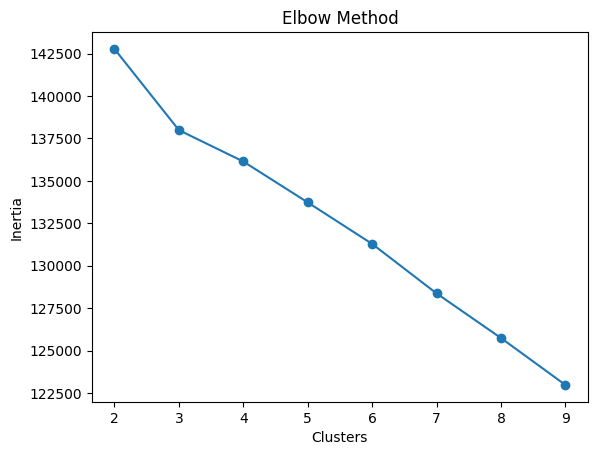


Silhouette Score: 0.14389088776781317

Cluster Summary:

         satisfaction_score        Age  client_type_Individual  gender_M  \
Cluster                                                                    
0                  3.266667  49.133333                1.000000  0.466667   
1                  3.021563  55.018868                0.948787  0.499326   
2                  3.035461  54.009456                0.945626  0.531915   
3                  3.089744  53.192308                0.948718  0.500000   

         country_Belgium  country_Canada  country_Denmark  country_France  \
Cluster                                                                     
0               0.000000        1.000000         0.000000        0.000000   
1               0.000000        0.000000         0.000000        0.000000   
2               0.101655        0.165485         0.023641        0.125296   
3               0.000000        0.000000         0.064103        0.000000   

         country_Germa

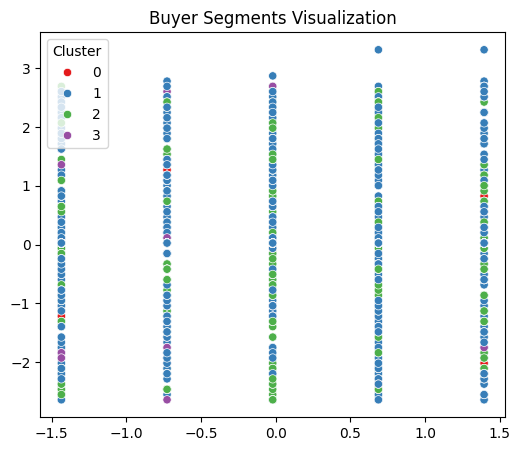

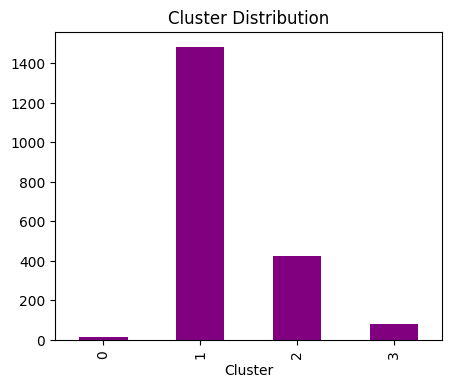

In [3]:
# ==========================================
# BUYER SEGMENTATION & INVESTMENT PROFILING
# REAL ESTATE MARKET INTELLIGENCE (FIXED)
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# -------------------------
# LOAD DATASET
# -------------------------
df = pd.read_csv("clients.csv")

print("Original Shape:", df.shape)

# -------------------------
# DROP UNNECESSARY COLUMNS
# -------------------------
df = df.drop(columns=['client_id', 'first_name', 'last_name'], errors='ignore')

# -------------------------
# DATE HANDLING → AGE
# -------------------------
df['date_of_birth'] = pd.to_datetime(df['date_of_birth'], errors='coerce')

df['Age'] = 2025 - df['date_of_birth'].dt.year

df = df.drop(columns=['date_of_birth'])

# -------------------------
# HANDLE MISSING VALUES
# -------------------------
# Fill numeric missing values
num_cols = df.select_dtypes(include=np.number).columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

# Fill categorical missing values
cat_cols = df.select_dtypes(include='object').columns
df[cat_cols] = df[cat_cols].fillna("Unknown")

# -------------------------
# ENCODING
# -------------------------
df = pd.get_dummies(df, drop_first=True)

# -------------------------
# FINAL CHECK FOR NaN
# -------------------------
df = df.fillna(0)

print("\nMissing Values After Cleaning:", df.isnull().sum().sum())

# -------------------------
# FEATURES
# -------------------------
X = df

# -------------------------
# SCALING
# -------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# -------------------------
# ELBOW METHOD
# -------------------------
inertia = []

for k in range(2, 10):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure()
plt.plot(range(2,10), inertia, marker='o')
plt.title("Elbow Method")
plt.xlabel("Clusters")
plt.ylabel("Inertia")
plt.show()

# -------------------------
# FINAL MODEL
# -------------------------
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# -------------------------
# SILHOUETTE SCORE
# -------------------------
score = silhouette_score(X_scaled, df['Cluster'])
print("\nSilhouette Score:", score)

# -------------------------
# CLUSTER SUMMARY
# -------------------------
print("\nCluster Summary:\n")
print(df.groupby('Cluster').mean(numeric_only=True))

# -------------------------
# VISUALIZATION
# -------------------------
plt.figure(figsize=(6,5))
sns.scatterplot(
    x=X_scaled[:,0],
    y=X_scaled[:,1],
    hue=df['Cluster'],
    palette='Set1'
)
plt.title("Buyer Segments Visualization")
plt.show()

# -------------------------
# CLUSTER DISTRIBUTION
# -------------------------
plt.figure(figsize=(5,4))
df['Cluster'].value_counts().sort_index().plot(kind='bar', color='purple')
plt.title("Cluster Distribution")
plt.show()